# Hotel Booking Demand — Exploratory Data Analysis


In [2]:
# importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

## Data Loading and Initial Exploration

In [3]:
data = pd.read_csv('data\hotel_bookings.csv')
data.head()

<>:1: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:1: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
C:\Users\Himanshu\AppData\Local\Temp\ipykernel_22160\2744967285.py:1: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  data = pd.read_csv('data\hotel_bookings.csv')


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
data.shape

(119390, 32)

Our dataset has 119390 rows and 32 columns

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [6]:
# checking for missing values
data.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

### missing value analysis

In [ ]:
missing_values = pd.DataFrame({
    "Missing Count": data.isnull().sum(),
    "Missing Percentage": (data.isnull().sum() / len(data)) * 100
})

missing_values = missing_values[
    missing_values["Missing Count"] > 0
].sort_values(by="Missing Percentage", ascending=False)

missing_values

,Missing Count,Missing Percentage
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350


In [8]:
# Handling missing values

# Missing children values: assume 0 children
data["children"] = data["children"].fillna(0).astype(int)

# Unknown country
data["country"] = data ["country"].fillna("Unknown")

# Missing agent/company IDs: use 0 as a placeholder
data["agent"] = data["agent"].fillna(0).astype(int)
data["company"] = data ["company"].fillna(0).astype(int)

In [9]:
# checking for missing values again
data.isnull().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                     0
adr                         

### Duplicate Records Analysis

In [12]:
# checking for duplicate values
duplicated_rows = data.duplicated().sum()
print(f"Number of duplicated rows: {duplicated_rows}")

duplicate_percentage = (duplicated_rows / len(data)) * 100

print(f"Duplicate Percentage: {duplicate_percentage:.2f}%")

Number of duplicated rows: 31994
Duplicate Percentage: 26.80%


### Investigating Duplicate Records

In [13]:
# Display records that have identical values
duplicate_records = data[data.duplicated(keep=False)]

duplicate_records.sort_values(
    by=["hotel", "arrival_date_year", "arrival_date_month"]
).head(10)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
40562,City Hotel,0,117,2015,August,31,1,2,1,1,...,No Deposit,17,0,0,Transient-Party,72.5,0,0,Check-Out,2015-08-04
40563,City Hotel,1,117,2015,August,31,1,2,1,2,...,No Deposit,17,0,0,Transient-Party,94.5,0,0,Canceled,2015-07-28
40564,City Hotel,1,117,2015,August,31,1,2,1,2,...,No Deposit,17,0,0,Transient-Party,94.5,0,0,Canceled,2015-07-28
40566,City Hotel,0,117,2015,August,31,1,2,1,2,...,No Deposit,17,0,0,Transient-Party,94.5,0,0,Check-Out,2015-08-04
40567,City Hotel,0,117,2015,August,31,1,2,1,2,...,No Deposit,17,0,0,Transient-Party,94.5,0,0,Check-Out,2015-08-04
40568,City Hotel,1,117,2015,August,31,1,2,1,2,...,No Deposit,17,0,0,Transient-Party,94.5,0,0,Canceled,2015-07-28
40569,City Hotel,1,117,2015,August,31,1,2,1,2,...,No Deposit,17,0,0,Transient-Party,94.5,0,0,Canceled,2015-07-28
40570,City Hotel,1,117,2015,August,31,1,2,1,2,...,No Deposit,17,0,0,Transient-Party,94.5,0,0,Canceled,2015-07-28
40573,City Hotel,1,117,2015,August,31,1,2,1,2,...,No Deposit,17,0,0,Transient-Party,94.5,0,0,Canceled,2015-07-28
40574,City Hotel,1,2,2015,August,31,1,2,1,2,...,No Deposit,17,0,0,Transient-Party,94.5,0,0,Canceled,2015-07-30


### Duplicate Records — Findings and Decision

**Observations:**
- Total records: 119,390
- Duplicate records: 31,994
- Duplicate percentage: 26.80%

**Decision: Retain duplicate records.**

**Justification:**

Although approximately 26.80% of the dataset consists of identical rows, these records cannot be conclusively classified as erroneous duplicates.

The dataset does not contain a unique booking identifier. Therefore, multiple legitimate bookings may share identical attributes, such as hotel type, arrival date, number of guests, room type, and booking details.

Removing these records without sufficient evidence could:
- Underestimate total booking volume.
- Distort cancellation rates and customer behavior patterns.
- Affect revenue estimates and seasonal demand analysis.

**Conclusion:**

All records will be retained for the primary analysis to avoid potentially removing valid bookings. The absence of unique booking identifiers is acknowledged as a data quality limitation.

### Data Type Conversion

In [14]:
# converting date columns to datetime format
data["reservation_status_date"] = pd.to_datetime(
    data["reservation_status_date"],
    errors="coerce"
)

In [15]:
print(data["reservation_status_date"].dtype)

print("Invalid dates:",
      data["reservation_status_date"].isna().sum())

datetime64[us]
Invalid dates: 0


### Feature Engineering

Creating additional features to improve our exploratory analysis.

In [17]:
# creating total night stays column
data["total_night_stays"] = (data["stays_in_weekend_nights"] + data["stays_in_week_nights"])

# creating total guests column
data["total_guests"] = (data["adults"] + data["children"] + data["babies"])

In [18]:
# verifying the new columns
data[[
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "total_night_stays",
    "adults",
    "children",
    "babies",
    "total_guests"
]].head(10)

,stays_in_weekend_nights,stays_in_week_nights,total_night_stays,adults,children,babies,total_guests
0,0,0,0,2,0,0,2
1,0,0,0,2,0,0,2
2,0,1,1,1,0,0,1
3,0,1,1,1,0,0,1
4,0,2,2,2,0,0,2
5,0,2,2,2,0,0,2
6,0,2,2,2,0,0,2
7,0,2,2,2,0,0,2
8,0,3,3,2,0,0,2
9,0,3,3,2,0,0,2


In [19]:
# new shape of dataset
data.shape

(119390, 34)

In [20]:
# creating arrival_date column
data["arrival_date"] = pd.to_datetime(
    data["arrival_date_year"].astype(str) + "-" +
    data["arrival_date_month"].astype(str) + "-" +
    data["arrival_date_day_of_month"].astype(str),
    errors="coerce"
)

In [ ]:
#verifying the arrival_date column
data[["arrival_date_year", "arrival_date_month", "arrival_date_day_of_month", "arrival_date"]].head(10)

,arrival_date_year,arrival_date_month,arrival_date_day_of_month,arrival_date
0,2015,July,1,2015-07-01
1,2015,July,1,2015-07-01
2,2015,July,1,2015-07-01
3,2015,July,1,2015-07-01
4,2015,July,1,2015-07-01
5,2015,July,1,2015-07-01
6,2015,July,1,2015-07-01
7,2015,July,1,2015-07-01
8,2015,July,1,2015-07-01
9,2015,July,1,2015-07-01


In [22]:
print("Invalid arrival dates:", data["arrival_date"].isna().sum())
print("Dataset shape:", data.shape)

Invalid arrival dates: 0
Dataset shape: (119390, 35)


### Data Quality Validation

checking for invalid bookings, including booking with zero guests and zero night stays

In [24]:
# bookings with zero guests
zero_guests = data[data["total_guests"] == 0]
print(f"Number of records with zero guests: {len(zero_guests)}")

Number of records with zero guests: 180


In [25]:
# booking with zero night stays
zero_night_stays = data[data["total_night_stays"] == 0]
print(f"Number of records with zero night stays: {len(zero_night_stays)}")

Number of records with zero night stays: 715


In [29]:
# checking for records with zero guests or zero night stays
invalid_bookings = data[(data["total_guests"] == 0) | (data["total_night_stays"] == 0)]
print(f'Number of potentially invalid bookings : {len(invalid_bookings)}')
print(f"Percentage of potentially invalid bookings: {round(len(invalid_bookings) / len(data) * 100, 2)}%")

Number of potentially invalid bookings : 825
Percentage of potentially invalid bookings: 0.69%


In [31]:
# investigating the records with zero guests and zero night stays
print("Zero guests:", (data["total_guests"] == 0).sum())

print("Zero nights:", (data["total_night_stays"] == 0).sum())

print("Both conditions:", (
    (data["total_guests"] == 0) &
    (data["total_night_stays"] == 0)
).sum())

Zero guests: 180
Zero nights: 715
Both conditions: 70


### Handling Potentially Invalid Bookings

#### Objective
To improve data quality by identifying and handling booking records with potentially invalid guest counts or stay durations while minimizing unnecessary data loss.

#### Observations
During data quality validation, the following records were identified:

- **180 bookings** had zero guests.
- **715 bookings** had zero stay nights.
- **70 bookings** satisfied both conditions.
- **825 unique bookings (0.69%)** were flagged as potentially invalid.

#### Cleaning Strategy

**1. Zero-Guest Bookings**

Bookings with zero recorded guests may indicate missing or inaccurate reservation information.

**Decision:** Exclude the 180 zero-guest bookings from the primary analysis because their validity cannot be established.

**2. Zero-Night Bookings**

Bookings with zero stay nights may represent cancellations, unusual reservations, or data entry issues.

**Decision:** Retain these records because they may contain valuable information for cancellation analysis. Exclude them only from calculations requiring a positive stay duration.

#### Expected Outcome
- Improve the reliability of guest-related analysis.
- Preserve potentially legitimate booking records.
- Reduce the risk of misleading results caused by questionable guest counts.
- Maintain transparency by documenting all cleaning assumptions.

**Note:** The original dataset will be preserved before filtering to allow comparison and sensitivity analysis. These exclusions are analytical decisions rather than confirmed corrections of erroneous records.

In [32]:
# Preserve the original dataset
data_original = data.copy()

# Remove bookings with zero guests
data = data[data["total_guests"] > 0].copy()

# Reset index
data.reset_index(drop=True, inplace=True)

print("Remaining records:", len(data))
print("Removed records:", len(data_original) - len(data))

Remaining records: 119210
Removed records: 180


C:\Users\Himanshu\AppData\Local\Temp\ipykernel_22160\2661305227.py:8: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.reset_index(drop=True, inplace=True)


### Outlier and Data Quality Assessment

**Objective:** Identify potentially unrealistic values in Average Daily Rate (ADR) and guest counts that could distort statistical analysis.

Outliers will be investigated before deciding whether to retain, modify, or exclude them.

In [ ]:
# checking adr values

print("Minimum ADR:", data["adr"].min())
print("Maximum ADR:", data["adr"].max())

print("Negative ADR records:", (data["adr"] < 0).sum())
print("Zero ADR records:", (data["adr"] == 0).sum())

Minimum ADR: -6.38
Maximum ADR: 5400.0
Negative ADR records: 1
Zero ADR records: 1810


In [34]:
# checking for guest counts
print("Minimum guests:", data["total_guests"].min())
print("Maximum guests:", data["total_guests"].max())

print("Bookings with more than 10 guests:",
      (data["total_guests"] > 10).sum())

Minimum guests: 1
Maximum guests: 55
Bookings with more than 10 guests: 14


### Investigating ADR Outliers

**Objective:** Examine unusual ADR values to identify potential data entry errors and determine appropriate cleaning strategies.

The initial assessment identified:
- 1 booking with negative ADR.
- 1,810 bookings with zero ADR.
- A maximum ADR of 5,400.

Negative ADR values are inconsistent with ordinary room pricing, while unusually high ADR values may represent luxury bookings, special arrangements, or data errors.

These records will be investigated before making any modifications.

In [35]:
# inspecting negative adr values
data.loc[
    data["adr"] < 0,
    ["hotel", "adr", "is_canceled",
     "total_night_stays", "total_guests",
     "reserved_room_type", "customer_type"]
]

,hotel,adr,is_canceled,total_night_stays,total_guests,reserved_room_type,customer_type
14962,Resort Hotel,-6.38,0,10,2,A,Transient-Party


In [36]:
# inspecting extemely high adr records
data.loc[
    data["adr"] > 1000,
    ["hotel", "adr", "is_canceled",
     "total_night_stays", "total_guests",
     "reserved_room_type", "customer_type"]
].sort_values("adr", ascending=False)

,hotel,adr,is_canceled,total_night_stays,total_guests,reserved_room_type,customer_type
48491,City Hotel,5400.0,1,1,2,A,Transient


#### Investigation of Extreme ADR Values

A single booking has an unusually high ADR of 5,400. Before deciding whether to exclude or retain this value, its booking characteristics will be examined.

The objective is to avoid removing legitimate high-value bookings while preventing potentially erroneous values from distorting pricing analysis.

In [39]:
data.loc[
    data["adr"] == 5400,
    [
        "hotel",
        "arrival_date",
        "adr",
        "is_canceled",
        "total_night_stays",
        "total_guests",
        "reserved_room_type",
        "assigned_room_type",
        "market_segment",
        "customer_type"
    ]
]

,hotel,arrival_date,adr,is_canceled,total_night_stays,total_guests,reserved_room_type,assigned_room_type,market_segment,customer_type
48491,City Hotel,2016-03-25,5400.0,1,1,2,A,A,Offline TA/TO,Transient


### ADR Outlier Treatment

**Findings:**
- One booking has a negative ADR of -6.38.
- One canceled booking has an unusually high ADR of 5,400.
- 1,810 bookings have an ADR of zero.

**Decision:**

All records will be retained in the primary dataset to preserve booking and cancellation information.

For the primary pricing analysis, ADR values below 0 or above 1,000 will be excluded. The upper threshold is a provisional analytical cutoff rather than a verified business rule.

Zero ADR values will be retained, as they may represent legitimate booking arrangements.

**Justification:**

This approach prevents extreme values from disproportionately influencing average pricing metrics while preserving the original booking records.

The impact of excluding these values should be assessed through sensitivity analysis.

### Pricing analysis

In [40]:
# Creating a separate dataset for pricing analysis
pricing_data = data[
    data["adr"].between(0, 1000)
].copy()

print("Original records:", len(data))
print("Pricing analysis records:", len(pricing_data))
print("Excluded records:", len(data) - len(pricing_data))

Original records: 119210
Pricing analysis records: 119208
Excluded records: 2


### Investigation of Unusually High Guest Counts

**Objective:** Investigate bookings with more than 10 guests to determine whether they represent legitimate group reservations or potential data quality issues.

Large guest counts are not necessarily incorrect, as hotels may accommodate group bookings. Therefore, these records will be examined before making any cleaning decisions.

In [44]:
high_guest_bookings = data[data["total_guests"] > 10]

print(
    high_guest_bookings[
        [
            "hotel",
            "total_guests",
            "adults",
            "children",
            "babies",
            "total_night_stays",
            "is_canceled",
            "customer_type"
        ]
    ].sort_values(
        by="total_guests",
        ascending=False
    ).to_string(index=False)
)


       hotel  total_guests  adults  children  babies  total_night_stays  is_canceled customer_type
Resort Hotel            55      55         0       0                  2            1         Group
Resort Hotel            50      50         0       0                  3            1         Group
Resort Hotel            40      40         0       0                  3            1         Group
Resort Hotel            27      27         0       0                  4            1         Group
Resort Hotel            27      27         0       0                  4            1         Group
Resort Hotel            26      26         0       0                  7            1         Group
Resort Hotel            26      26         0       0                  7            1         Group
Resort Hotel            26      26         0       0                  7            1         Group
Resort Hotel            26      26         0       0                  7            1         Group
Resort Hot

#### High Guest Count — Findings and Decision

**Findings:**

The dataset contains 14 bookings with more than 10 guests.

- 13 bookings belong to Resort Hotels, while 1 belongs to a City Hotel.
- 12 Resort Hotel bookings are classified as Group bookings, and all were canceled.
- 1 Resort Hotel booking is classified as Contract, containing 2 adults and 10 children.
- 1 City Hotel booking is classified as Transient, containing 2 adults and 10 babies.

**Decision:** Retain all 14 records because there is insufficient evidence to classify them as erroneous. The unusually high number of babies will be documented as a potential data quality concern.

### Final Data Quality Verification

**Objective:** Verify the integrity of the dataset after preprocessing and ensure it is ready for exploratory data analysis.

The final checks include:
- Dataset dimensions
- Remaining missing values
- Duplicate records
- Zero-guest bookings
- Invalid dates
- ADR values requiring special treatment

In [46]:
print("Dataset Shape:", data.shape)

print("Missing Values:", data.isnull().sum().sum())

print("Duplicate Records:", data.duplicated().sum())

print("Zero Guest Bookings:", (data["total_guests"] == 0).sum())

print("Zero Night Bookings:", (data["total_night_stays"] == 0).sum())

print("Invalid Arrival Dates:", data["arrival_date"].isna().sum())

print("Invalid Reservation Dates:",
      data["reservation_status_date"].isna().sum())

print("Pricing Analysis Records:", len(pricing_data))

Dataset Shape: (119210, 35)
Missing Values: 0
Duplicate Records: 31980
Zero Guest Bookings: 0
Zero Night Bookings: 645
Invalid Arrival Dates: 0
Invalid Reservation Dates: 0
Pricing Analysis Records: 119208


## EDA

### BASIC LEVEL ANALYSIS

#### Q1:  What is the average lead time for bookings?
**Objective:** Calculate the average number of days customers book their hotel stays in advance.

**Business Relevance:** Understanding booking lead time helps hotel management forecast demand, plan room availability, and develop targeted marketing strategies.

In [47]:
avg_lead_time = data["lead_time"].mean()

print(f"Average Booking Lead Time: {avg_lead_time:.2f} days")

Average Booking Lead Time: 104.11 days


In [48]:
data['lead_time'].describe()

count    119210.000000
mean        104.109227
std         106.875450
min           0.000000
25%          18.000000
50%          69.000000
75%         161.000000
max         737.000000
Name: lead_time, dtype: float64

##### Findings and Business Insights

**Findings:**
- Average booking lead time: **104.11 days**
- Median booking lead time: **69 days**
- Standard deviation: **106.88 days**
- Lead times range from 0 to 737 days.

The mean exceeds the median, suggesting a positively skewed distribution influenced by bookings made far in advance.

**Business Insights:**

- **Demand Forecasting:** Hotels can use booking lead-time patterns to improve demand forecasts and room inventory planning.
- **Marketing Strategy:** Advance-booking campaigns could target customers who plan their stays several months ahead.
- **Cancellation Management:** Hotels should investigate whether longer booking lead times are associated with higher cancellation rates.

**Recommendation:**

Segment customers into short-, medium-, and long-lead-time groups to better understand booking behavior and develop targeted pricing and promotional strategies.

#### Question 2: What is the distribution of bookings by hotel type?

**Objective:** Compare booking volumes between City Hotels and Resort Hotels.

**Business Relevance:** Understanding the distribution of bookings helps management evaluate demand across hotel types and allocate marketing and operational resources.

In [68]:
# booking counts
hotel_counts = data["hotel"].value_counts()
hotel_percentage = data["hotel"].value_counts(normalize=True) * 100

print("Hotel Booking Counts:")
print(hotel_counts)
print("----------------")
print(f"Hotel Booking Percentages:")
print(f"{hotel_percentage.round(2)}%")

Hotel Booking Counts:
hotel
City Hotel      79163
Resort Hotel    40047
Name: count, dtype: int64
----------------
Hotel Booking Percentages:
hotel
City Hotel      66.41
Resort Hotel    33.59
Name: proportion, dtype: float64%


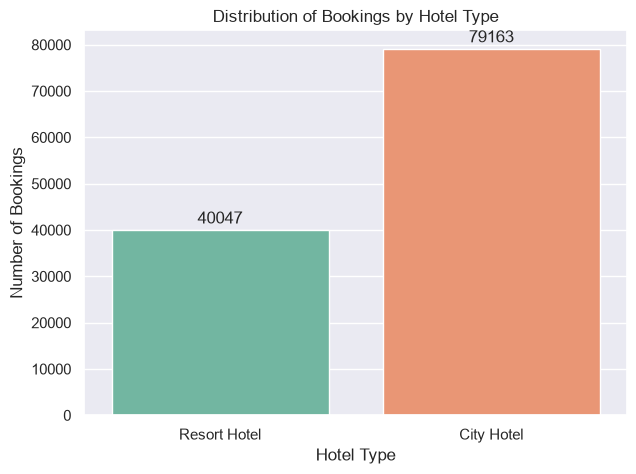

In [62]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=data,
    x="hotel",
    hue="hotel",
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=2)

plt.title("Distribution of Bookings by Hotel Type", fontsize=12)
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")
plt.show()

##### Findings and Business Insights

**Findings:**
- City Hotels received 79,163 bookings, representing 66.41% of the dataset.
- Resort Hotels received 40,047 bookings, representing 33.59%.
- City Hotels recorded approximately twice the booking volume of Resort Hotels.

**Business Insights:**

City Hotels account for the majority of recorded reservations, suggesting stronger booking demand within the dataset.

However, booking counts alone cannot establish which hotel type performs better financially, as hotel capacity, cancellation rates, room pricing, and stay duration may differ.

**Recommendations:**

- Analyze cancellation rates separately for City Hotels and Resort Hotels.
- Compare average daily rates and booking patterns to better understand financial performance.
- Investigate seasonal demand differences to support staffing and promotional planning.

#### Questions 3–10: Booking Patterns and Guest Behavior

This section explores cancellations, arrival months, special requests,
guest origins, hotel pricing, parking requirements, stay durations,
and travel agent involvement.

In [69]:
# Q3. How many bookings were canceled?
canceled = data["is_canceled"].sum()
cancellation_rate = data["is_canceled"].mean() * 100

print(f"Q3 | Canceled Bookings: {canceled:,}")
print(f"Cancellation Rate: {cancellation_rate:.2f}%")


# Q4. Most common arrival month
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_bookings = (
    data["arrival_date_month"]
    .value_counts()
    .reindex(month_order, fill_value=0)
)

print("\nQ4 | Most Common Arrival Month:")
print(monthly_bookings.sort_values(ascending=False).head())


# Q5. Average special requests per booking
avg_requests = data["total_of_special_requests"].mean()

print(f"\nQ5 | Average Special Requests: {avg_requests:.2f}")


# Q6. Country with the highest number of bookings
print("\nQ6 | Top 5 Countries:")
print(data["country"].value_counts().head())


# Q7. Average ADR by hotel type
avg_adr = pricing_data.groupby("hotel")["adr"].mean()

print("\nQ7 | Average ADR by Hotel:")
print(avg_adr.round(2))


# Q8. Percentage of bookings requiring parking
parking_percentage = (
    data["required_car_parking_spaces"].gt(0).mean() * 100
)

print(f"\nQ8 | Parking Required: {parking_percentage:.2f}%")


# Q9. Average stay duration
stay_stats = data[
    ["stays_in_week_nights", "stays_in_weekend_nights", "total_night_stays"]
].mean()

print("\nQ9 | Average Stay Duration:")
print(stay_stats.round(2))


# Q10. Bookings through travel agents
# Assumption: agent=0 represents missing agent information
agent_bookings = data["agent"].ne(0).sum()

print(f"\nQ10 | Bookings with Recorded Agent ID: {agent_bookings:,}")


Q3 | Canceled Bookings: 44,199
Cancellation Rate: 37.08%

Q4 | Most Common Arrival Month:
arrival_date_month
August     13861
July       12644
May        11780
October    11147
April      11078
Name: count, dtype: int64

Q5 | Average Special Requests: 0.57

Q6 | Top 5 Countries:
country
PRT    48483
GBR    12120
FRA    10401
ESP     8560
DEU     7285
Name: count, dtype: int64

Q7 | Average ADR by Hotel:
hotel
City Hotel      105.44
Resort Hotel     94.99
Name: adr, dtype: float64

Q8 | Parking Required: 6.22%

Q9 | Average Stay Duration:
stays_in_week_nights       2.50
stays_in_weekend_nights    0.93
total_night_stays          3.43
dtype: float64

Q10 | Bookings with Recorded Agent ID: 102,930


#### Basic EDA — Key Findings and Business Recommendations

**1. Booking Cancellations**

Out of 119,210 bookings, 44,199 were canceled, resulting in a cancellation rate of 37.08%.

**Business Implication:** Cancellations represent a significant operational challenge. Management should investigate cancellation patterns across hotel types, booking channels, and lead times to improve demand forecasting and reservation management.

**2. Seasonal Booking Demand**

August recorded the highest number of bookings (13,861), followed by July (12,644) and May (11,780).

**Business Implication:** Higher recorded booking volumes during these months suggest opportunities for seasonal staffing, inventory planning, and targeted marketing. Actual occupancy should be evaluated separately.

**3. Guest Preferences and Origins**

- Average special requests per booking: 0.57
- Largest recorded country of origin: Portugal (48,483 bookings)
- Other major countries: United Kingdom, France, Spain, and Germany
- Bookings requiring parking: 6.22%

**Business Implication:** Guest origin and service-request patterns can help hotels develop targeted marketing campaigns and allocate operational resources.

**4. Hotel Pricing**

- City Hotel average ADR: 105.44
- Resort Hotel average ADR: 94.99

**Business Implication:** City Hotels have a higher average recorded daily rate. However, differences in room types, seasonality, booking status, and guest characteristics should be considered before drawing conclusions about pricing performance.

**5. Stay Duration**

- Average weekday nights: 2.50
- Average weekend nights: 0.93
- Average total stay duration: 3.43 nights

**Business Implication:** Stay-duration patterns can support room inventory planning, housekeeping schedules, and promotional package design.

**6. Travel Agent Involvement**

102,930 bookings have a recorded travel agent identifier, representing approximately 86.34% of retained bookings.

**Business Implication:** Travel agency relationships may represent an important distribution channel. However, missing agent identifiers cannot conclusively establish that the remaining bookings were made directly.

### Overall Recommendations

- Investigate factors associated with booking cancellations.
- Prepare operational resources for high-demand arrival months.
- Develop market-specific promotional strategies.
- Compare hotel pricing across seasons and customer segments.
- Use booking and stay-duration patterns to improve resource planning.

**Analysis Limitations:** The dataset contains reservations rather than verified occupied room-nights. Booking counts do not directly measure occupancy, and ADR alone does not measure realized revenue.

###  Intermediate Exploratory Data Analysis

This section investigates cancellation behavior, pricing differences,
booking channels, customer loyalty, seasonal trends, and room preferences.

The objective is to identify relationships that can support operational
and revenue management decisions.

In [71]:

# Q11. Cancellation rate by hotel type
cancellation_by_hotel = (
    data.groupby("hotel")["is_canceled"].mean() * 100
)
print("\nQ11 | Cancellation Rate by Hotel (%)")
print(cancellation_by_hotel.round(2))


# Q12. Average ADR by market segment
adr_by_segment = (
    pricing_data.groupby("market_segment")["adr"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)
print("\nQ12 | Average ADR by Market Segment")
print(adr_by_segment.round(2))


# Q13. Relationship between lead time and cancellations
lead_time_corr = data["lead_time"].corr(data["is_canceled"])

lead_time_bins = [-1, 7, 30, 90, 180, float("inf")]
lead_time_labels = ["0-7", "8-30", "31-90", "91-180", "181+"]

data["lead_time_group"] = pd.cut(
    data["lead_time"],
    bins=lead_time_bins,
    labels=lead_time_labels
)

lead_time_cancellation = (
    data.groupby("lead_time_group", observed=True)
    .agg(
        bookings=("is_canceled", "size"),
        cancellation_rate=("is_canceled", "mean")
    )
)

lead_time_cancellation["cancellation_rate"] *= 100

print("\nQ13 | Lead Time and Cancellation")
print("Correlation:", round(lead_time_corr, 3))
print(lead_time_cancellation.round(2))


# Q14. Bookings by distribution channel
channel_bookings = data["distribution_channel"].value_counts()

print("\nQ14 | Distribution Channels")
print(channel_bookings)


# Q15. Previous cancellations by hotel type
previous_cancellations = (
    data.groupby("hotel")["previous_cancellations"].mean()
)

print("\nQ15 | Average Previous Cancellations")
print(previous_cancellations.round(3))


# Q16. ADR trends over the years
adr_yearly = (
    pricing_data.groupby("arrival_date_year")["adr"].mean()
)

print("\nQ16 | Average ADR by Year")
print(adr_yearly.round(2))


# Q17. Month with highest estimated room revenue
# Only non-canceled bookings with positive stay duration
revenue_data = pricing_data[
    (pricing_data["is_canceled"] == 0) &
    (pricing_data["total_night_stays"] > 0)
].copy()

revenue_data["estimated_room_revenue"] = (
    revenue_data["adr"] * revenue_data["total_night_stays"]
)

monthly_revenue = (
    revenue_data.groupby("arrival_date_month")["estimated_room_revenue"]
    .sum()
    .reindex(month_order)
)

print("\nQ17 | Estimated Room Revenue by Month")
print(monthly_revenue.sort_values(ascending=False).round(2))


# Q18. Special requests vs ADR
special_requests_adr = (
    pricing_data.groupby("total_of_special_requests")["adr"]
    .agg(["mean", "count"])
)

print("\nQ18 | Special Requests vs ADR")
print(special_requests_adr.round(2))


# Q19. Average stay duration: repeated vs new guests
guest_stay = (
    data.groupby("is_repeated_guest")["total_night_stays"]
    .agg(["mean", "median", "count"])
)

guest_stay.index = guest_stay.index.map({
    0: "New Guest",
    1: "Repeated Guest"
})

print("\nQ19 | Stay Duration by Guest Type")
print(guest_stay.round(2))


# Q20. Most booked room types
room_bookings = data["reserved_room_type"].value_counts()

print("\nQ20 | Most Booked Room Types")
print(room_bookings)



Q11 | Cancellation Rate by Hotel (%)
hotel
City Hotel      41.79
Resort Hotel    27.77
Name: is_canceled, dtype: float64

Q12 | Average ADR by Market Segment
                  mean  count
market_segment               
Online TA       117.32  56408
Direct          115.63  12582
Aviation        100.99    235
Offline TA/TO    87.26  24181
Groups           79.56  19790
Corporate        69.53   5282
Undefined        15.00      2
Complementary     2.95    728

Q13 | Lead Time and Cancellation
Correlation: 0.293
                 bookings  cancellation_rate
lead_time_group                             
0-7                 19635               9.60
8-30                18945              27.89
31-90               29529              37.73
91-180              26420              44.74
181+                24681              57.01

Q14 | Distribution Channels
distribution_channel
TA/TO        97750
Direct       14611
Corporate     6651
GDS            193
Undefined        5
Name: count, dtype: int64

Q

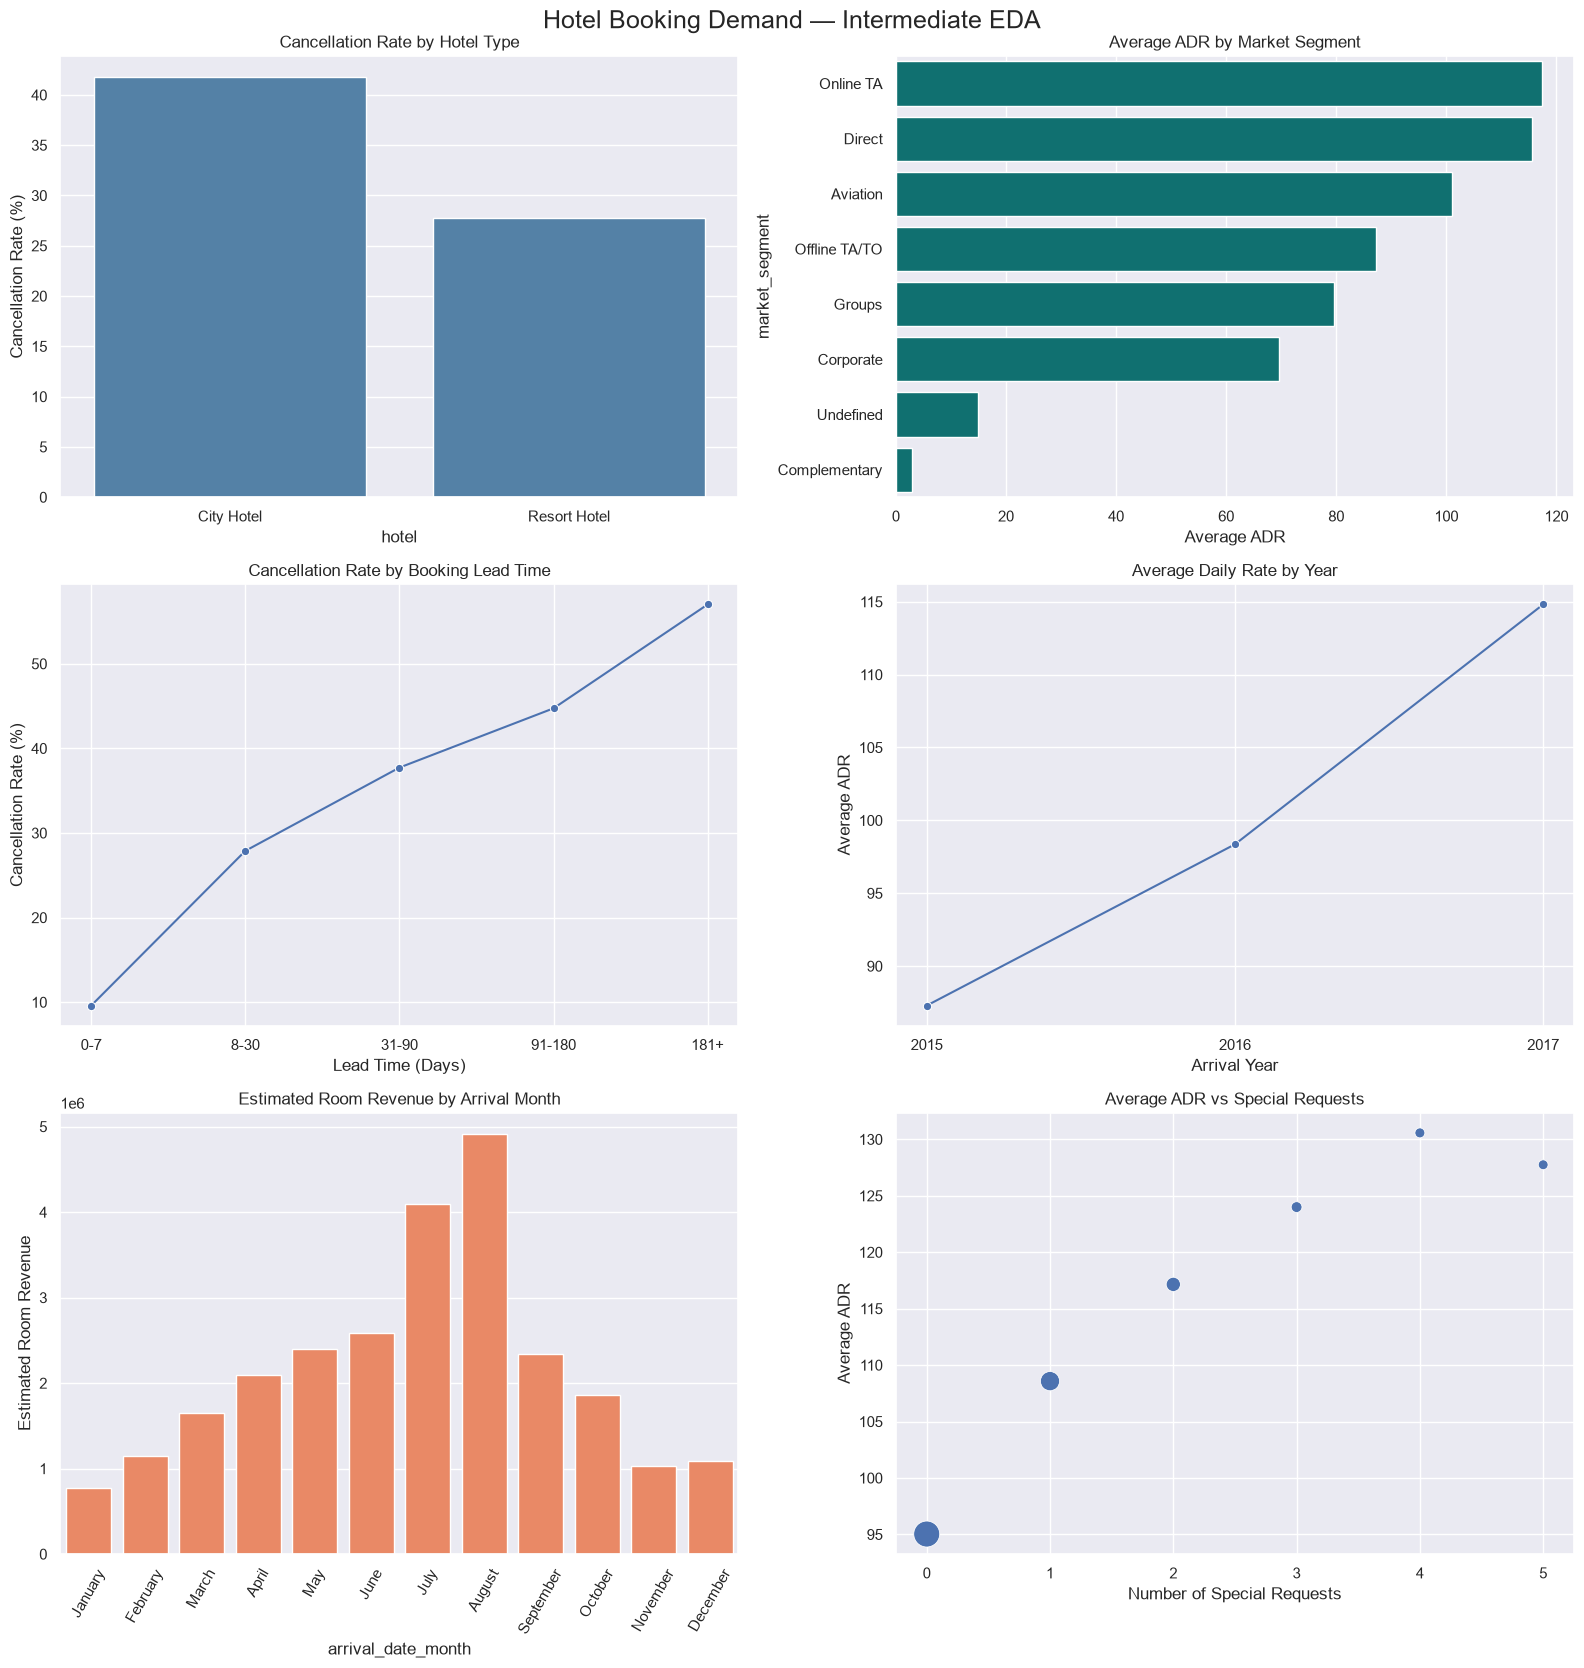

In [72]:

fig, axes = plt.subplots(3, 2, figsize=(16, 17))

# Q11. Cancellation rates by hotel
sns.barplot(
    x=cancellation_by_hotel.index,
    y=cancellation_by_hotel.values,
    color="steelblue",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Cancellation Rate by Hotel Type")
axes[0, 0].set_ylabel("Cancellation Rate (%)")

# Q12. ADR by market segment
sns.barplot(
    x=adr_by_segment["mean"],
    y=adr_by_segment.index,
    color="teal",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Average ADR by Market Segment")
axes[0, 1].set_xlabel("Average ADR")

# Q13. Lead time vs cancellation
sns.lineplot(
    x=lead_time_cancellation.index.astype(str),
    y=lead_time_cancellation["cancellation_rate"],
    marker="o",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Cancellation Rate by Booking Lead Time")
axes[1, 0].set_xlabel("Lead Time (Days)")
axes[1, 0].set_ylabel("Cancellation Rate (%)")

# Q16. ADR trends over time
sns.lineplot(
    x=adr_yearly.index,
    y=adr_yearly.values,
    marker="o",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Average Daily Rate by Year")
axes[1, 1].set_xlabel("Arrival Year")
axes[1, 1].set_ylabel("Average ADR")
axes[1, 1].set_xticks(adr_yearly.index)

# Q17. Estimated room revenue by month
sns.barplot(
    x=monthly_revenue.index,
    y=monthly_revenue.values,
    color="coral",
    ax=axes[2, 0]
)
axes[2, 0].set_title("Estimated Room Revenue by Arrival Month")
axes[2, 0].tick_params(axis="x", rotation=60)
axes[2, 0].set_ylabel("Estimated Room Revenue")

# Q18. Special requests vs ADR
sns.scatterplot(
    x=special_requests_adr.index,
    y=special_requests_adr["mean"],
    size=special_requests_adr["count"],
    sizes=(50, 350),
    legend=False,
    ax=axes[2, 1]
)
axes[2, 1].set_title("Average ADR vs Special Requests")
axes[2, 1].set_xlabel("Number of Special Requests")
axes[2, 1].set_ylabel("Average ADR")

plt.suptitle("Hotel Booking Demand — Intermediate EDA", fontsize=18)
plt.tight_layout()
plt.show()


#### Intermediate EDA — Findings and Business Recommendations

**Q11. Cancellation Rate by Hotel Type**

City Hotels recorded a cancellation rate of 41.79%, compared with 27.77% for Resort Hotels, a difference of 14.02 percentage points.

**Recommendation:** Investigate hotel-specific cancellation policies, customer segments, and booking channels to understand the difference.

**Q12. ADR by Market Segment**

Online Travel Agents (117.32) and Direct bookings (115.63) recorded the highest average ADR among the major market segments. Corporate bookings had a lower average ADR of 69.53.

The Aviation segment recorded an ADR of 100.99 but had only 235 observations. Undefined and Complementary segments require special interpretation because of their small sample sizes or nonstandard pricing.

**Recommendation:** Evaluate segment profitability alongside distribution costs, cancellations, and booking volumes rather than relying on ADR alone.

**Q13. Lead Time and Cancellation**

Cancellation rates increased from 9.60% for bookings made 0–7 days in advance to 57.01% for bookings made more than 180 days in advance.

The Pearson correlation between lead time and cancellation status was 0.293, indicating a positive association.

**Recommendation:** Investigate whether confirmation reminders, deposit policies, or flexible rebooking options can reduce cancellations among long-lead-time reservations.

**Q14. Distribution Channels**

Travel Agents/Tour Operators (TA/TO) accounted for 97,750 bookings, making them the dominant recorded distribution channel.

**Recommendation:** Assess dependence on intermediaries and compare channel-level cancellation rates, acquisition costs, and realized revenue.

**Q15. Previous Cancellations**

The average number of previous cancellations was 0.080 for City Hotels and 0.102 for Resort Hotels.

Although Resort Hotels recorded a slightly higher historical cancellation average, their current booking cancellation rate was lower.

**Recommendation:** Evaluate previous cancellations as a potential predictor of future cancellation behavior.

**Q16. ADR Trends**

Average ADR increased across the recorded arrival years:

- 2015: 87.29
- 2016: 98.36
- 2017: 114.81

These are descriptive annual averages. Because the dataset covers incomplete calendar years, this trend should not be interpreted as proof of sustained price growth.

**Q17. Estimated Room Revenue**

August generated the highest estimated room revenue at approximately 4.92 million dataset currency units, followed by July at approximately 4.10 million.

The estimates use ADR multiplied by booked nights for non-canceled reservations with positive stay durations.

**Recommendation:** Evaluate summer demand and pricing opportunities while validating estimates against actual completed stays and financial records.

**Q18. Special Requests and ADR**

Average ADR generally increased with the number of special requests, from 95.03 for bookings with no requests to 130.57 for bookings with four requests.

The five-request category contained only 40 bookings.

**Interpretation:** Special requests and ADR are associated, but this does not establish that special requests cause higher prices or indicate greater guest satisfaction.

**Q19. New vs. Repeated Guests**

New guests had an average stay duration of 3.47 nights, compared with 1.95 nights for repeated guests.

**Recommendation:** Explore whether repeated guests favor shorter visits, particular hotel types, or specific booking channels.

**Q20. Reserved Room Types**

Room type A dominated reservations with 85,873 bookings, followed by type D with 19,179.

**Recommendation:** Compare room demand against room capacity, pricing, and cancellation patterns before making inventory allocation decisions.

### Overall Intermediate EDA Conclusion

The analysis identifies booking lead time, hotel type, distribution channels, and seasonal demand as important areas for further investigation.

The strongest actionable opportunity is to understand and potentially reduce cancellations among long-lead-time bookings, particularly at City Hotels.

These observational findings should be validated through further modeling and operational testing before implementing major policy changes.

### ADVANCE ANALYSIS

In [74]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import roc_auc_score, r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [75]:
# Q21. What factors are most strongly associated with hotel booking cancellations?

# Select potential factors influencing cancellation
cancel_features = [
    "lead_time",
    "total_night_stays",
    "total_guests",
    "previous_cancellations",
    "booking_changes",
    "total_of_special_requests",
    "is_repeated_guest",
    "hotel",
    "market_segment",
    "deposit_type"
]

# Convert categorical columns into numerical dummy variables
X_cancel = pd.get_dummies(
    data[cancel_features],
    drop_first=True,
    dtype=int
)

# Target variable: 1 = canceled, 0 = not canceled
y_cancel = data["is_canceled"]

# Split into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X_cancel,
    y_cancel,
    test_size=0.2,
    random_state=42,
    stratify=y_cancel
)

# Standardize features and train logistic regression
cancel_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

cancel_model.fit(X_train, y_train)

# Predict cancellation probabilities
cancel_probabilities = cancel_model.predict_proba(X_test)[:, 1]

# Evaluate model discrimination
cancel_auc = roc_auc_score(y_test, cancel_probabilities)

# Extract model coefficients
cancel_coefficients = pd.Series(
    cancel_model.named_steps["logisticregression"].coef_[0],
    index=X_cancel.columns
).sort_values()

print("Q21 | Cancellation Model")
print(f"ROC-AUC: {cancel_auc:.3f}")

print("\nTop Positive Coefficients:")
print(cancel_coefficients.tail(10).round(3))

print("\nTop Negative Coefficients:")
print(cancel_coefficients.head(10).round(3))

Q21 | Cancellation Model
ROC-AUC: 0.828

Top Positive Coefficients:
hotel_Resort Hotel             -0.096
market_segment_Complementary   -0.031
deposit_type_Refundable        -0.010
market_segment_Undefined        0.030
total_guests                    0.144
total_night_stays               0.162
market_segment_Online TA        0.414
lead_time                       0.420
previous_cancellations          1.371
deposit_type_Non Refund         1.883
dtype: float64

Top Negative Coefficients:
total_of_special_requests      -0.591
market_segment_Offline TA/TO   -0.323
booking_changes                -0.290
is_repeated_guest              -0.207
market_segment_Groups          -0.124
market_segment_Direct          -0.110
market_segment_Corporate       -0.101
hotel_Resort Hotel             -0.096
market_segment_Complementary   -0.031
deposit_type_Refundable        -0.010
dtype: float64


In [76]:
# Q22. How do guest composition and booking characteristics relate to Average Daily Rate (ADR)?

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# Step 1: Select relevant predictors
guest_features = [
    "adults",
    "children",
    "babies",
    "total_night_stays",
    "hotel",
    "reserved_room_type",
    "arrival_date_month"
]

# Step 2: Select valid pricing records with positive stays
adr_model_data = pricing_data[
    pricing_data["total_night_stays"] > 0
].copy()

# Step 3: Convert categorical variables into numerical columns
X_adr = pd.get_dummies(
    adr_model_data[guest_features],
    drop_first=True,
    dtype=int
)

# Step 4: Define target variable
y_adr = adr_model_data["adr"]

# Step 5: Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X_adr,
    y_adr,
    test_size=0.2,
    random_state=42
)

# Step 6: Train linear regression model
adr_model = LinearRegression()
adr_model.fit(X_train, y_train)

# Step 7: Generate predictions
adr_predictions = adr_model.predict(X_test)

# Step 8: Evaluate model
print("Q22 | ADR Regression")
print(f"R² Score: {r2_score(y_test, adr_predictions):.3f}")
print(f"Mean Absolute Error: {mean_absolute_error(y_test, adr_predictions):.2f}")

# Step 9: Examine guest composition coefficients
adr_coefficients = pd.Series(
    adr_model.coef_,
    index=X_adr.columns
)

print("\nGuest Composition Coefficients:")
print(
    adr_coefficients.reindex(
        ["adults", "children", "babies"]
    ).round(3)
)


Q22 | ADR Regression
R² Score: 0.451
Mean Absolute Error: 25.62

Guest Composition Coefficients:
adults       8.034
children    18.473
babies       3.942
dtype: float64


In [77]:

# Q23. Is there a relationship between booking changes and special requests?

# Group bookings by the number of changes made
booking_changes_requests = (
    data.groupby("booking_changes")
    .agg(
        avg_special_requests=("total_of_special_requests", "mean"),
        bookings=("total_of_special_requests", "size")
    )
)

# Calculate Pearson correlation
changes_requests_corr = data[
    ["booking_changes", "total_of_special_requests"]
].corr().iloc[0, 1]

print("Q23 | Booking Changes vs Special Requests")
print(f"Correlation: {changes_requests_corr:.3f}")
print(booking_changes_requests.head(12).round(3))


Q23 | Booking Changes vs Special Requests
Correlation: 0.055
                 avg_special_requests  bookings
booking_changes                                
0                               0.556    101232
1                               0.625     12666
2                               0.713      3780
3                               0.818       914
4                               0.820       367
5                               0.826       115
6                               0.918        61
7                               0.655        29
8                               1.000        14
9                               0.125         8
10                              1.667         6
11                              0.000         1


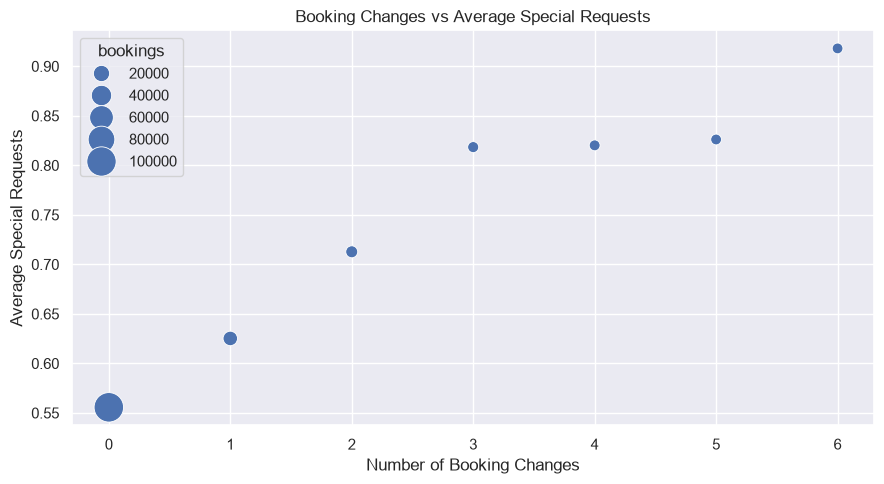

In [78]:
# Visualize the relationship between booking changes and special requests

# Exclude very small groups to avoid misleading comparisons
changes_plot = booking_changes_requests[
    booking_changes_requests["bookings"] >= 30
].reset_index()

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=changes_plot,
    x="booking_changes",
    y="avg_special_requests",
    size="bookings",
    sizes=(60, 450),
    legend="brief"
)

plt.title("Booking Changes vs Average Special Requests")
plt.xlabel("Number of Booking Changes")
plt.ylabel("Average Special Requests")
plt.tight_layout()
plt.show()


In [79]:

# Q24. How do hotel booking cancellation rates vary across different arrival months?

# Step 1: Calculate cancellation rates and booking counts by month
seasonal_cancellations = (
    data.groupby("arrival_date_month")["is_canceled"]
    .agg(["mean", "count"])
    .reindex(month_order)
)

# Step 2: Convert cancellation proportions to percentages
seasonal_cancellations["mean"] *= 100

# Step 3: Rename columns for better readability
seasonal_cancellations = seasonal_cancellations.rename(
    columns={
        "mean": "cancellation_rate",
        "count": "total_bookings"
    }
)

# Step 4: Display results
print("Q24 | Cancellation Rate by Arrival Month")
print(seasonal_cancellations.round(2))


Q24 | Cancellation Rate by Arrival Month
                    cancellation_rate  total_bookings
arrival_date_month                                   
January                         30.50            5921
February                        33.45            8052
March                           32.23            9768
April                           40.78           11078
May                             39.70           11780
June                            41.49           10929
July                            37.46           12644
August                          37.78           13861
September                       39.19           10500
October                         38.09           11147
November                        31.31            6771
December                        35.03            6759


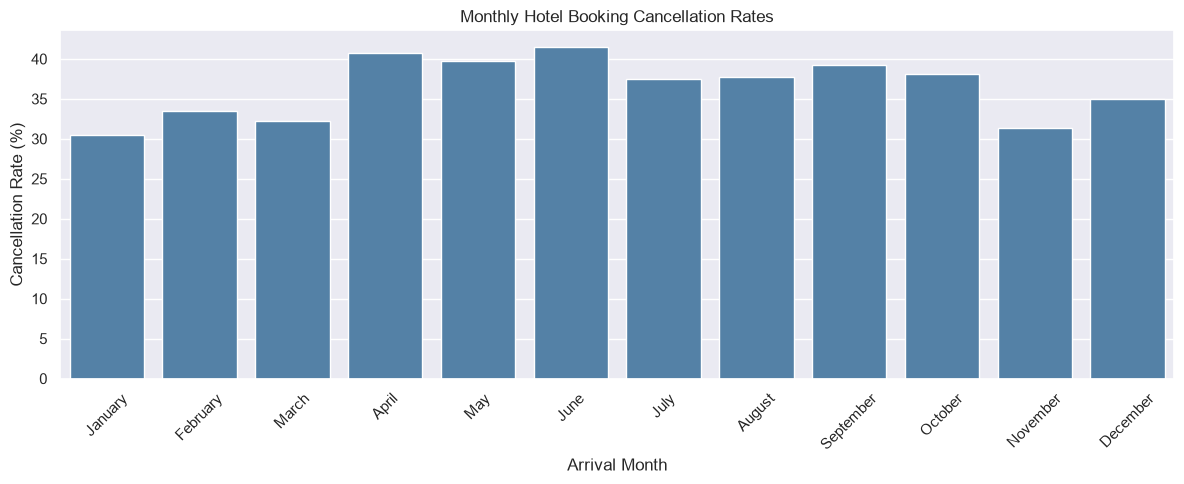

In [ ]:

# Visualize cancellation rates across arrival months

plt.figure(figsize=(12, 5))

sns.barplot(
    data=seasonal_cancellations.reset_index(),
    x="arrival_date_month",
    y="cancellation_rate",
    color="steelblue"
)

plt.title("Monthly Hotel Booking Cancellation Rates")
plt.xlabel("Arrival Month")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [81]:

# Q25. How does the distribution of booking lead times vary across different market segments?

# Step 1: Group bookings by market segment
# Step 2: Calculate mean, median, and booking count
segment_lead_time = (
    data.groupby("market_segment")["lead_time"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

# Step 3: Display results
print("Q25 | Lead Time by Market Segment")
print(segment_lead_time.round(2))


Q25 | Lead Time by Market Segment
                  mean  median  count
market_segment                       
Groups          187.09   162.0  19791
Offline TA/TO   135.10   109.0  24182
Online TA        83.07    58.0  56408
Direct           49.90    16.0  12582
Corporate        22.14     7.0   5282
Complementary    13.55     3.0    728
Aviation          4.47     3.0    235
Undefined         1.50     1.5      2


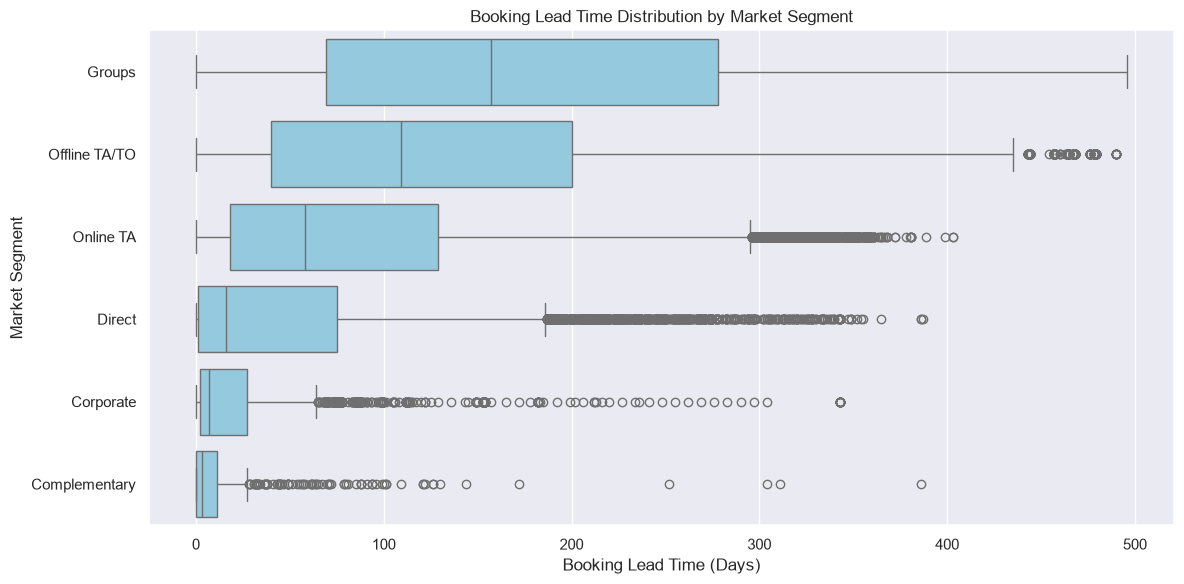

In [82]:

#  Visualize booking lead time distribution across market segments

# Select market segments with at least 500 bookings
major_segments = segment_lead_time[
    segment_lead_time["count"] >= 500
].index

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=data[
        (data["market_segment"].isin(major_segments)) &
        (data["lead_time"] <= 500)
    ],
    x="lead_time",
    y="market_segment",
    order=major_segments,
    color="skyblue"
)

plt.title("Booking Lead Time Distribution by Market Segment")
plt.xlabel("Booking Lead Time (Days)")
plt.ylabel("Market Segment")
plt.tight_layout()
plt.show()


#### Advanced EDA — Findings and Business Insights

##### Q21. Factors Associated with Booking Cancellations

**Key Findings:**

- The Logistic Regression model achieved a **ROC-AUC score of 0.828**, demonstrating good discrimination between canceled and non-canceled bookings on the held-out test dataset.
- Non-refundable deposits (coefficient: 1.883) and previous cancellations (1.371) showed the strongest positive standardized associations with cancellation likelihood.
- Booking lead time (0.420) and Online Travel Agent bookings (0.414) were also positively associated with cancellations.
- Special requests (-0.591), booking changes (-0.290), and repeated-guest status (-0.207) showed negative associations with cancellation likelihood.

**Business Insights:**

Previous cancellation history, deposit policies, and booking lead time are important characteristics to investigate when evaluating cancellation risk.

Hotels should consider targeted booking reminders and reconfirmation strategies for long-lead-time reservations. The association between non-refundable deposits and cancellations warrants further investigation before making policy changes.

**Limitation:** Regression coefficients represent statistical associations, not causal effects. Certain booking characteristics may change after the initial reservation, making the model unsuitable for booking-time prediction without further validation.

---

##### Q22. Guest Composition and Average Daily Rate (ADR)

**Key Findings:**

- The Multiple Linear Regression model achieved an **R² score of 0.451**, explaining approximately 45.1% of ADR variation in the test dataset.
- The Mean Absolute Error (MAE) was **25.62**, indicating an average absolute prediction error of 25.62 dataset currency units.
- Guest composition coefficients were:
  - Adults: +8.034
  - Children: +18.473
  - Babies: +3.942
- All three guest composition variables showed positive associations with ADR after accounting for the other modeled characteristics.

**Business Insights:**

Guest composition is associated with hotel room pricing, although hotel type, room category, stay duration, and seasonality also contribute to observed ADR differences.

Hotels could further investigate family-oriented pricing strategies and room packages. However, the model's moderate explanatory power suggests that additional pricing factors should be considered before making operational decisions.

**Limitation:** These coefficients do not establish that adding a guest directly causes the corresponding increase in room price.

---

##### Q23. Booking Changes and Special Requests

**Key Findings:**

- The Pearson correlation between booking changes and special requests was **0.055**, indicating a very weak positive linear relationship.
- Bookings with no changes had an average of 0.556 special requests.
- Bookings with three changes had an average of 0.818 special requests.
- Bookings with six changes had an average of 0.918 special requests.
- Approximately 84.9% of bookings (101,232) had no recorded booking changes.
- Groups with high numbers of booking changes contained relatively few observations.

**Business Insights:**

Although average special requests generally increased across the more common booking-change groups, the overall correlation was extremely weak.

Booking modifications alone are therefore unlikely to provide a useful indication of special-request volume.

Hotels should monitor booking changes and special requests separately when planning administrative and guest service resources.

**Limitation:** Special requests and booking changes do not directly measure customer satisfaction, and the analysis cannot establish a causal relationship.

---

##### Q24. Seasonal Cancellation Patterns

**Key Findings:**

- June recorded the highest cancellation rate at **41.49%**, followed by April at 40.78% and May at 39.70%.
- January recorded the lowest cancellation rate at **30.50%**.
- August had the highest booking volume (13,861 bookings), but its cancellation rate was 37.78%.
- Cancellation rates varied across arrival months, indicating differences in seasonal booking behavior.

**Business Insights:**

Higher cancellation rates during certain months can create uncertainty in room inventory planning and expected revenue.

Hotels could investigate seasonal cancellation policies, booking lead times, and customer segments to understand these differences.

Demand forecasting should incorporate both booking volumes and cancellation rates rather than relying on reservations alone.

**Limitation:** Monthly results aggregate bookings across multiple years, and the dataset does not cover complete calendar years at both ends of the observation period.

---

##### Q25. Booking Lead Time by Market Segment

**Key Findings:**

- Group bookings had the longest average lead time at **187.09 days**, with a median of 162 days.
- Offline Travel Agent/Tour Operator bookings averaged 135.10 days.
- Online Travel Agent bookings averaged 83.07 days.
- Direct bookings averaged 49.90 days, with a median of 16 days.
- Corporate bookings averaged 22.14 days, with a median of 7 days.
- The mean exceeded the median across major market segments, suggesting positively skewed lead-time distributions.

**Business Insights:**

Different market segments exhibit distinct booking behaviors.

Group and Offline TA/TO reservations are generally made farther in advance, while Corporate and Direct bookings tend to occur closer to arrival.

Hotels could develop segment-specific reservation management strategies, including earlier confirmations for group reservations and short-lead-time promotional campaigns for appropriate customer segments.

Since longer booking lead times were also associated with higher cancellation rates, market-segment differences should be considered when investigating cancellation risk.

---

### Overall Advanced EDA Conclusion

The advanced analysis identified several important patterns in hotel booking behavior:

1. **Cancellation risk:** Previous cancellation history, deposit type, and booking lead time showed notable associations with cancellation outcomes.
2. **Pricing behavior:** Guest composition was positively associated with ADR, although the regression model explained only part of the observed pricing variation.
3. **Guest interactions:** Booking changes and special requests exhibited a very weak overall linear relationship.
4. **Seasonality:** Cancellation rates varied across arrival months, with June recording the highest rate.
5. **Customer segmentation:** Group and travel agency bookings generally had longer lead times than Direct and Corporate bookings.

**Overall Business Recommendation:**

Elite Hotels International should prioritize further investigation of cancellation patterns, particularly among long-lead-time reservations and selected market segments. Combining booking behavior, pricing characteristics, and seasonal demand analysis could improve reservation management, operational planning, and revenue forecasting.

These findings are observational and should be validated through additional analysis or controlled operational testing before major policy changes.

_______________________________________________________________________________________________________